### **I. Description de la base de données**

Pour illustrer la mise en œuvre du test de Jeffreys, nous avons retenu la base de données publique HMEQ, disponible sur Kaggle. Elle regroupe les informations de près de 6 000 demandeurs de prêts immobiliers. Notre attention se porte sur la variable binaire 'BAD' : elle prend la valeur 1 lorsque le client fait défaut — ce qui représente 20 % de notre échantillon, soit 1 189 cas — et 0 si le crédit est remboursé. 
Nous disposons également de 12 variables explicatives pour modéliser cette probabilité de défaut.  

Ces variables sont notamment;

| Nom de la variable | Libellé en anglais | Libellé en français |
| :--- | :--- | :--- |
| **BAD** | 1 = client defaulted on loan; 0 = loan repaid | 1 = client en défaut de paiement ; 0 = prêt remboursé |
| **LOAN** | Amount of the loan request | Montant de la demande de prêt |
| **MORTDUE** | Amount due on existing mortgage | Montant dû sur un prêt immobilier existant |
| **VALUE** | Value of current property | Valeur du bien immobilier actuel |
| **REASON** | DebtCon = debt consolidation; HomeImp = home improvement | DebtCon = consolidation de dettes ; HomeImp = amélioration de l’habitat |
| **JOB** | Six occupational categories | Six catégories professionnelles |
| **YOJ** | Years at present job | Années à l’emploi actuel |
| **DEROG** | Number of major derogatory reports | Nombre de rapports défavorables majeurs |
| **DELINQ** | Number of delinquent credit lines | Nombre de lignes de crédit en retard |
| **CLAGE** | Age of oldest trade line in months | Âge de la plus ancienne ligne commerciale en mois |
| **NINQ** | Number of recent credit lines | Nombre de lignes de crédit récentes |
| **CLNO** | Number of credit lines | Nombre de lignes de crédit |
| **DEBTINC** | Debt-to-income ratio | Ratio dette/revenu |


### **II. Importation de la base de données et traitement préalable à l'application du test de jeffreys**

#### **II.1 importation du dataset**

In [17]:
import pandas as pd
import numpy as np
from imblearn.under_sampling import RandomUnderSampler # pip install imblearn
from sklearn.model_selection import train_test_split
# import kagglehub # 
pip install kagglehub
from kagglehub import KaggleDatasetAdapter
import os
from statsmodels.stats.outliers_influence import variance_inflation_factor
#from optbinning import OptimalBinning # 
pip install optbinning


# 1. Télécharger la dernière version du dataset
path = kagglehub.dataset_download("ajay1735/hmeq-data")

# 2. Lister les fichiers pour trouver le nom exact du CSV
files = os.listdir(path)

# 3. Charger le fichier CSV (généralement hmeq.csv)
# On combine le chemin du dossier avec le nom du fichier
csv_path = os.path.join(path, "hmeq.csv")
df = pd.read_csv(csv_path)

print("Succès ! Voici les 5 premières lignes :")
print("-------------------")
print(df.head());


SyntaxError: invalid syntax (854978875.py, line 6)

***Commentaire***: : On remarque avec les premières lignes de notre dataset que nos données contiennent des valeurs manquantes, il faut donc les traiter avant toutes choses.

#### **II.2 Prétraitement de la base**

***II.2.1. Visualisation du nombres de valeurs manquantes par variables***

In [2]:
## Aperçu des données
print("-------------------")
print(len(df))
print("-------------------")
print(df.isnull().sum())

-------------------
5960
-------------------
BAD           0
LOAN          0
MORTDUE     518
VALUE       112
REASON      252
JOB         279
YOJ         515
DEROG       708
DELINQ      580
CLAGE       308
NINQ        510
CLNO        222
DEBTINC    1267
dtype: int64


***II.2.2. Nettoyage rapide (essentiel pour la base HMEQ car il y a des valeurs manquantes)***

In [3]:
# Pour l'approche IRB, on remplit souvent par la médiane ou on crée des catégories 'Missing'
df['JOB'] = df['JOB'].fillna('Other')
df['REASON'] = df['REASON'].fillna('Unknown')
df = df.fillna(df.median(numeric_only=True))

# Encodage des variables catégorielles (nécessaire pour le modèle)
#df = pd.get_dummies(df, columns=['JOB', 'REASON'], drop_first=True)

# 3. Définition des variables
X = df.drop('BAD', axis=1)  # 'BAD' est notre variable cible (1 = défaut, 0 = sain)
y = df['BAD']

print(f"Taux de défaut initial : {y.mean():.2%}")

Taux de défaut initial : 19.95%


In [4]:
## Aperçu des données
print("-------------------")
print(len(df))
print("-------------------")
print(df.isnull().sum())

-------------------
5960
-------------------
BAD        0
LOAN       0
MORTDUE    0
VALUE      0
REASON     0
JOB        0
YOJ        0
DEROG      0
DELINQ     0
CLAGE      0
NINQ       0
CLNO       0
DEBTINC    0
dtype: int64


***II.2.3. Reduction du taux de défaut à 5%***  

Cette réduction a un double objectif : elle renforce les garanties de confidentialité et réduit les effets néfastes du déséquilibre des classes sur l'estimation et la validation du modèle (Brown et Mues, 2012 ; Fitzpatrick et Mues, 2016 ; Chen et al., 2024).

In [5]:
# 4. Sous-échantillonnage à 5% (Méthode exacte de l'article)
# Séparer les deux classes
df_sains = df[df['BAD'] == 0]
df_defauts = df[df['BAD'] == 1]

# Calculer combien de défauts on doit garder pour en avoir 5% au total
# Formule : n_defauts / (n_defauts + n_sains) = 0.05
# Ce qui donne : n_defauts = (0.05 * n_sains) / 0.95
n_sains = len(df_sains)
n_defauts_a_garder = int((0.05 * n_sains) / 0.95)

# Sous-échantillonner les défauts (on réduit les '1')
np.random.seed(123)
df_defauts_reduit = df_defauts.sample(n=n_defauts_a_garder, random_state=42)

# Fusionner pour créer la nouvelle base
df_final = pd.concat([df_sains, df_defauts_reduit]).sample(frac=1, random_state=42)

print(f"Nombre de clients sains : {len(df_sains)}")
print(f"Nombre de défauts gardés : {len(df_defauts_reduit)}")
print(f"Nouveau taux de défaut : {df_final['BAD'].mean():.2%}")

Nombre de clients sains : 4771
Nombre de défauts gardés : 251
Nouveau taux de défaut : 5.00%


***II.2.4-Gestion de la multicolinéarité(Corrélation & VIF)*** 

Pour le developpement d'un modèle de regression logistique, il est important de ne pas avoir de multicolinéarité entre les variables.  
On commence par filtrer les variables trop corrélées entre elles pour éviter l'instabilité des coefficients.

In [6]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

# On ne travaille que sur les variables numériques pour le VIF
X_numeric = df_final.select_dtypes(include=[np.number]).drop(columns=['BAD'])

def reduce_vif(df, threshold=5.0):
    variables = list(df.columns)
    dropped = True
    while dropped:
        dropped = False
        vif = [variance_inflation_factor(df[variables].values, i) for i in range(len(variables))]
        max_vif = max(vif)
        if max_vif > threshold:
            max_idx = vif.index(max_vif)
            print(f"Suppression de {variables[max_idx]} (VIF: {max_vif:.2f})")
            del variables[max_idx]
            dropped = True
    return df[variables]

# Application du filtre
print ("Les variables supprimées:")
X_reduced = reduce_vif(X_numeric)

print ("\n----------------------")

print ("Les variables restantes sont:")
print(X_reduced.columns)

Les variables supprimées:
Suppression de VALUE (VIF: 18.10)
Suppression de DEBTINC (VIF: 10.31)
Suppression de CLNO (VIF: 6.35)

----------------------
Les variables restantes sont:
Index(['LOAN', 'MORTDUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ'], dtype='object')


***II.2.5-Discrétisation des variables continues***  

Cette étape est cruciale dans l'approche IRB. Les banques préfèrent transformer les variables continues (comme l'âge ou le revenu) en "tranches" (binning) car cela permet de capturer des relations non-linéaires et rend le modèle plus robuste aux valeurs aberrantes.  

Pour discrétiser en maximisant le Gini (ou l'Information Value), la bibliothèque la plus utilisée est optbinning. Elle gère automatiquement la contrainte de "5 classes maximum".


In [7]:
from sklearn.tree import DecisionTreeClassifier

# On va stocker les variables discrétisées
X_binned = pd.DataFrame()
target = df_final['BAD']

for col in X_reduced.columns:
    # 1. Utiliser un arbre de décision pour trouver les seuils optimaux (Gini)
    # max_leaf_nodes=5 garantit un maximum de 5 classes (bins)
    tree = DecisionTreeClassifier(max_leaf_nodes=5, random_state=42)
    
    # On reshape les données car l'arbre attend un tableau 2D
    x_val = X_reduced[col].values.reshape(-1, 1)
    tree.fit(x_val, target)
    
    # 2. On récupère les seuils de décision
    # On utilise 'apply' pour savoir dans quel bin (feuille de l'arbre) tombe chaque valeur
    X_binned[col + '_bin'] = tree.apply(x_val)
    
    # Facultatif : afficher le nombre de bins créés pour cette variable
    n_bins = X_binned[col + '_bin'].nunique()
    print(f"Variable {col} discrétisée en {n_bins} bins.")

# 3. Ajouter les variables catégorielles d'origine (JOB, REASON)
for col in ['JOB', 'REASON']:
    if col in df_final.columns:
        X_binned[col] = df_final[col].values

print("------------------\n")
X_binned.info()

Variable LOAN discrétisée en 5 bins.
Variable MORTDUE discrétisée en 5 bins.
Variable YOJ discrétisée en 5 bins.
Variable DEROG discrétisée en 5 bins.
Variable DELINQ discrétisée en 5 bins.
Variable CLAGE discrétisée en 5 bins.
Variable NINQ discrétisée en 5 bins.
------------------

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5022 entries, 0 to 5021
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   LOAN_bin     5022 non-null   int64 
 1   MORTDUE_bin  5022 non-null   int64 
 2   YOJ_bin      5022 non-null   int64 
 3   DEROG_bin    5022 non-null   int64 
 4   DELINQ_bin   5022 non-null   int64 
 5   CLAGE_bin    5022 non-null   int64 
 6   NINQ_bin     5022 non-null   int64 
 7   JOB          5022 non-null   object
 8   REASON       5022 non-null   object
dtypes: int64(7), object(2)
memory usage: 353.2+ KB


***II.2.6. Encodage One-Hot final*** 

Une fois que tout est en catégories, on transforme ces catégories en colonnes binaires (0 ou 1) pour que la régression logistique puisse les traiter correctement.

In [8]:
# 1. Identifier les colonnes binées (celles qui finissent par '_bin')
bin_cols = [col for col in X_binned.columns if col.endswith('_bin')]

# 2. Convertir ces colonnes en type 'category' pour que get_dummies les reconnaisse
for col in bin_cols:
    X_binned[col] = X_binned[col].astype('category')

# 3. Lancer l'encodage One-Hot sur l'ensemble du DataFrame
# drop_first=True est essentiel pour la stabilité du modèle IRB (évite la colinéarité)
X_final = pd.get_dummies(X_binned, drop_first=True)

# 4. Vérification
print(f"Nombre de variables après prétraitement : {X_final.shape[1]}","\n")
print(X_final.head(3),"\n")

Nombre de variables après prétraitement : 35 

   LOAN_bin_4  LOAN_bin_6  LOAN_bin_7  LOAN_bin_8  MORTDUE_bin_4  \
0       False       False       False        True          False   
1       False       False        True       False          False   
2        True       False       False       False          False   

   MORTDUE_bin_6  MORTDUE_bin_7  MORTDUE_bin_8  YOJ_bin_4  YOJ_bin_5  ...  \
0           True          False          False      False      False  ...   
1           True          False          False      False       True  ...   
2          False          False          False      False       True  ...   

   NINQ_bin_6  NINQ_bin_7  NINQ_bin_8  JOB_Office  JOB_Other  JOB_ProfExe  \
0       False       False       False       False       True        False   
1       False       False       False       False      False        False   
2       False       False       False       False      False         True   

   JOB_Sales  JOB_Self  REASON_HomeImp  REASON_Unknown  
0    

### **III. Mise en place des phases de developpement et de validation de données des modèles**

> Avant toutes choses , il est primordial de séparer la base de données en trois pour suivent les étapes des banques dans le cadre IFR. 

La répartition des données s'est fait ainsi  et pour:

- Ensemble de Développement (90 %) : Utilisé pour créer et calibrer le modèle.

    - Train (80 % du total) : Pour ajuster les coefficients de la régression.

    - Test (10 % du total) : Pour valider la performance et choisir les variables.

- Ensemble de Validation / Out-of-Sample (10 %) : Utilisé uniquement pour le backtesting final (tests de Clopper-Pearson/Jeffreys).


> ***Récap du Flux de travail du partitionnement et de validation (Approche IRB)***  


| Phase de l'étude | Sous-ensemble | Proportion du total | Objectif méthodologique |
| :--- | :--- | :--- | :--- |
| **1.Différenciation** | **Entraînement (Train)** | 80% | Ajustement du modèle de notation (calcul des coefficients $\beta$). |
| **2.Sélection** | **Test** | 10% | Évaluation des performances et choix de la spécification finale du modèle. |
| **3.Quantification** | **Développement (Train + Test)** | 90% | Calcul des Probabilités de Défaut (PD) calibrées sur l'échantillon complet. |
| **4.Backtesting** | **Validation (Out-of-sample)** | 10% | Évaluation finale à l'aide des tests binomiaux (Clopper-Pearson) et Jeffreys. |

> ***Code de division de la base de données en 3***

In [9]:
from sklearn.model_selection import train_test_split

np.random.seed(123)
y_resampled = df_final['BAD']

# 1. Première séparation : Isoler les 10% de Validation (Backtesting)
# Le reste (90%) constitue l'ensemble de Développement
np.random.seed(123)
X_dev, X_valid, y_dev, y_valid = train_test_split(
    X_final, y_resampled, 
    test_size=0.10, 
    random_state=42, 
    stratify=y_resampled
)

# 2. Deuxième séparation : Diviser le Développement (90%) en Train et Test
# Pour obtenir 80% du total en Train et 10% du total en Test :
# On doit prendre 1/9ème du bloc de Développement pour le Test (soit environ 11.11%)
np.random.seed(123)
X_train, X_test, y_train, y_test = train_test_split(
    X_dev, y_dev, 
    test_size=1/9, 
    random_state=42, 
    stratify=y_dev
)

# Vérification des proportions et des taux de défaut
def verif_taux(name, y_subset):
    print(f"{name:12} | Taille: {len(y_subset)} | Taux Défaut: {y_subset.mean():.2%}")

print("--- Vérification du Partitionnement ---")
verif_taux("Train (80%)", y_train)
verif_taux("Test (10%)", y_test)
verif_taux("Valid (10%)", y_valid)

--- Vérification du Partitionnement ---
Train (80%)  | Taille: 4016 | Taux Défaut: 5.00%
Test (10%)   | Taille: 503 | Taux Défaut: 4.97%
Valid (10%)  | Taille: 503 | Taux Défaut: 4.97%


#### **III.1 Etape 1: Différentiation du risque sur l'ensemble d'entrainement du modèle ( Développement du modèle de PD et segmentation du risque)**

***III.1.1 Modèle de regression logistique sur l'ensemble d'entrainement et sélection de variables les plus significatives***

On applique le stepwise et en Python, on utilise souvent la Recursive Feature Elimination (RFE) pour simuler ce processus.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

# Initialisation du modèle de base
np.random.seed(123)
model = LogisticRegression(max_iter=1000, solver='lbfgs')

# Application de la sélection automatique (RFE)
# On demande par exemple de garder les 10 meilleures variables
np.random.seed(123)
selector = RFE(model, n_features_to_select=10, step=1)
selector = selector.fit(X_train, y_train)

# Variables conservées
selected_features = X_train.columns[selector.support_]
print(f"Variables sélectionnées : {list(selected_features)}")

# Mise à jour des ensembles avec uniquement les variables retenues
X_train_final = X_train[selected_features]
X_test_final = X_test[selected_features]

Variables sélectionnées : ['LOAN_bin_4', 'LOAN_bin_7', 'LOAN_bin_8', 'DEROG_bin_4', 'DEROG_bin_7', 'DELINQ_bin_3', 'CLAGE_bin_5', 'CLAGE_bin_8', 'NINQ_bin_7', 'JOB_Self']


***III.1.2 Modèle de regression logistique final avec seulement les variables significatives***

Une fois les variables sélectionnées, on entraîne le modèle sur l'ensemble d'entraînement (80%). La régression logistique est choisie ici pour son interprétabilité, un critère clé pour les régulateurs bancaires.

In [11]:
# Entraînement final
np.random.seed(123)
irb_model = LogisticRegression(max_iter=1000)
irb_model.fit(X_train_final, y_train)

# Récupération des coefficients (Interprétabilité)
coefficients = pd.DataFrame({
    'Variable': selected_features,
    'Coefficient': irb_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("\nCoefficients du modèle (Interprétabilité IRB) :")
print(coefficients)


Coefficients du modèle (Interprétabilité IRB) :
       Variable  Coefficient
4   DEROG_bin_7     1.456551
8    NINQ_bin_7     1.295537
7   CLAGE_bin_8     1.224280
3   DEROG_bin_4     1.193543
9      JOB_Self     0.970295
6   CLAGE_bin_5    -1.054325
1    LOAN_bin_7    -1.079967
5  DELINQ_bin_3    -1.278492
2    LOAN_bin_8    -1.393828
0    LOAN_bin_4    -1.674219


***III.1.3 Calcul des probabilité de défauts prédites de chaque individu de l'ensemble de développement***

In [12]:
import pandas as pd
from scipy.stats import chi2_contingency, kruskal


# 1. On recrée X_dev en s'assurant d'avoir les mêmes colonnes que X_train_final
# On utilise .reindex pour ajouter les colonnes manquantes (avec des 0) 
# et supprimer les colonnes inédites.
X_dev = pd.concat([X_train, X_test]).reindex(columns=X_train_final.columns, fill_value=0)

# 2. Recréation de l'ensemble de réponse (y) pour le développement (90%)
y_dev_actual = pd.concat([y_train, y_test])

# 3. Calcul des PD sur l'ensemble de développement (90%)
# X_dev contient Train + Test
pd_dev = irb_model.predict_proba(X_dev)[:, 1]

***III.1.4 Assigner des classes de risque à chaque individu de l'ensemble de développement*** 

On utilise pour cela un binning par quantiles pour sa simplicité et son interprétabilité. En divisant les PD en 4 groupes (quartiles), On s'assure que chaque catégorie de risque contient environ 25% des clients de votre ensemble de développement.  

- Classe 1 : Risque très faible.
- Classe 2 : Risque modéré.
- Classe 3 : Risque élevé.
- Classe 4 : Risque très élevé.  

Nous allons effectuer cette segmentation sur l'ensemble de développement (Train + Test) comme recommandé pour stabiliser les estimations.

In [13]:
import pandas as pd
from scipy.stats import chi2_contingency, kruskal


# 1. Création des 4 classes de risque par quantiles (q=4)
# 'labels=False' donne des scores de 0 à 3
risk_groups = pd.qcut(pd_dev, q=4, labels=['Très Faible', 'Modéré', 'Élevé', 'Très Élevé'])

# Création d'un DataFrame de synthèse pour les tests
df_groups = pd.DataFrame({
    'PD_Predite': pd_dev,
    'Classe_Risque': risk_groups,
    'Defaut_Reel': y_dev_actual
})

# 2. Calcul du taux de défaut moyen par classe
summary = df_groups.groupby('Classe_Risque', observed=True)['Defaut_Reel'].agg(['sum','mean', 'count'])
summary.columns = ['nombre de defauts','Taux_Defaut_Observed', 'Nombre_Contrats']
print(summary)

               nombre de defauts  Taux_Defaut_Observed  Nombre_Contrats
Classe_Risque                                                          
Très Faible                   15              0.010431             1438
Modéré                        39              0.029817             1308
Élevé                         34              0.047619              714
Très Élevé                   138              0.130312             1059


#### **III.2 Etape 2: Evaluation du modèle final final sur l'ensemble test**

In [14]:
from sklearn.metrics import roc_auc_score

# Prédiction des probabilités sur l'ensemble de test
y_test_pred = irb_model.predict_proba(X_test_final)[:, 1]

# Calcul de l'AUC (Performance de différenciation)
auc_test = roc_auc_score(y_test, y_test_pred)
gini_test = 2 * auc_test - 1

print(f"\nPerformance sur l'ensemble de Test :")
print(f"AUC : {auc_test:.4f}")
print(f"Gini : {gini_test:.4f}")


Performance sur l'ensemble de Test :
AUC : 0.7849
Gini : 0.5699


#### **III.3 Etape 3: Quantification du risque sur l'ensemble de développement(test + entrainement)**

A la fin de l'étape 1 de différenciation , nous avons un modèle qui prédit plus ou moins bien les défauts ou différencie bien les risques.  

A présent , il est question de segmenter les individus en catégories de risque et de calculer les probabilités de défauts calibrés.  

***III.3.1 Calcul des probabilité de défaut prédites de chaque individu de l'ensemble de développement***

In [15]:
import pandas as pd
from scipy.stats import chi2_contingency, kruskal


# 1. On recrée X_dev en s'assurant d'avoir les mêmes colonnes que X_train_final
# On utilise .reindex pour ajouter les colonnes manquantes (avec des 0) 
# et supprimer les colonnes inédites.
np.random.seed(123)
X_dev = pd.concat([X_train, X_test]).reindex(columns=X_train_final.columns, fill_value=0)

# 2. Recréation de l'ensemble de réponse (y) pour le développement (90%)
y_dev_actual = pd.concat([y_train, y_test])

# 3. Calcul des PD sur l'ensemble de développement (90%)
# X_dev contient Train + Test
pd_dev = irb_model.predict_proba(X_dev)[:, 1]

***III.3.2 Assigner des classes de risque à chaque individu de l'ensemble de développement*** 

On utilise pour cela un binning par quantiles pour sa simplicité et son interprétabilité. En divisant les PD en 4 groupes (quartiles), On s'assure que chaque catégorie de risque contient environ 25% des clients de votre ensemble de développement.  

- Classe 1 : Risque très faible.
- Classe 2 : Risque modéré.
- Classe 3 : Risque élevé.
- Classe 4 : Risque très élevé.  

Nous allons effectuer cette segmentation sur l'ensemble de développement (Train + Test) comme recommandé pour stabiliser les estimations.

In [16]:
# 2. Création des classes de risque SANS labels pour obtenir les intervalles
# On utilise retbins=True pour récupérer les valeurs de coupure
np.random.seed(123)
risk_series, bins = pd.qcut(pd_dev, q=4, retbins=True)

# 3. Création du DataFrame de synthèse avec les intervalles textuels
df_groups = pd.DataFrame({
    'PD_Predite': pd_dev,
    'Classe_Risque': risk_series, # Ici, les labels seront les intervalles (ex: [0.01, 0.03])
    'Defaut_Reel': y_dev_actual.values
})



print("les classes de risques crées sont")
print(df_groups["Classe_Risque"].value_counts())

les classes de risques crées sont
Classe_Risque
(0.010700000000000001, 0.0155]    1438
(0.0155, 0.033]                   1308
(0.0535, 0.895]                   1059
(0.033, 0.0535]                    714
Name: count, dtype: int64



***III.3.3 Validation de l'hétérogénéité*** 

A ce stade nous effectuons deux tests statistiques pour confirmer que les classes sont bien distinctes les unes des autres :

- **Test du Chi-carré** : Pour vérifier si la fréquence des défauts dépend de la classe de risque.

- **Test de Kruskal-Wallis** : Pour comparer les distributions des PD entre les groupes.

==> ***Interprétation des résultats***  

Si vos p-values sont inférieures à 0,05, cela confirme une hétérogénéité significative entre les groupes. Cela signifie que votre segmentation n'est pas due au hasard et que le modèle arrive réellement à isoler des poches de risque très différentes.


In [17]:
# Test du Chi-carré
contingency_table = pd.crosstab(df_groups['Classe_Risque'], df_groups['Defaut_Reel'])
chi2, p_chi2, _, _ = chi2_contingency(contingency_table)

# Test de Kruskal-Wallis
# On compare les PD prédites de chaque groupe
groups_data = [df_groups[df_groups['Classe_Risque'] == g]['PD_Predite'] for g in df_groups['Classe_Risque'].unique()]
stat_kw, p_kw = kruskal(*groups_data)

print(f"\nTest du Chi-carré : p-value = {p_chi2:.4e}")
print(f"Test de Kruskal-Wallis : p-value = {p_kw:.4e}")


Test du Chi-carré : p-value = 1.2406e-43
Test de Kruskal-Wallis : p-value = 0.0000e+00


***Commentaire*** : Nos P.value sont inférieurs à 0.05 , ce qui confirme une hétérogénéité significative entre nos classes de risques.

***III.3.4 Quantification du risque à proprement dit (calcul des PD_k)***

Cette étape à pour objectif de calculer les probabilités de défauts calibrées c'est à dire les probabilités de défaut observées moyennes pour chaque catégorie de risque.  

Selon la méthodologie, on utilise la moyenne des individus au sein de chaque catégorie pour refléter les pratiques bancaires de calcul des moyennes à long terme.

In [18]:
import pandas as pd

# 1. Calcul du résumé combiné
# On agrège 'Defaut_Reel' pour la réalité et 'PD_Predite' pour la calibration
summary = df_groups.groupby('Classe_Risque', observed=True).agg({
    'Defaut_Reel': ['sum', 'count', 'mean'],
    'PD_Predite': 'mean'
})

# 2. Nettoyage des noms de colonnes (pour enlever le multi-index)
summary.columns = [
    'Nombre de défauts', 
    'Nombre_Contrats', 
    'Taux_Défaut_Observé_dev', 
    'PD_Long_Run'
]

# 3. Insertion des labels qualitatifs
labels = ['Très Faible', 'Modéré', 'Élevé', 'Très Élevé']
summary.insert(0, 'Label', labels)

# 4. On applique l'arrondi sur l'ensemble du DataFrame
summary = summary.round(4)

# 5. Affichage du résultat final

print("--- Résumé final conforme à l'approche IRB ---")
display(summary)

--- Résumé final conforme à l'approche IRB ---


,Label,Nombre de défauts,Nombre_Contrats,Taux_Défaut_Observé_dev,PD_Long_Run
Classe_Risque,,,,,
"(0.010700000000000001, 0.0155]",Très Faible,15,1438,0.0104,0.0127
"(0.0155, 0.033]",Modéré,39,1308,0.0298,0.0306
"(0.033, 0.0535]",Élevé,34,714,0.0476,0.0441
"(0.0535, 0.895]",Très Élevé,138,1059,0.1303,0.1283


#### **III.4 Etape 4: Black testing**

Cette étape finale de Backtesting est le juge de paix de notre modèle IRB. Elle consiste à confronter nos prédictions à des données totalement neuves (les 10 % de validation) pour vérifier si le modèle "survit" à la réalité.

Nous allonns ainsi procéder à l'implémentation de cette procédure, incluant l'évaluation du conservatisme selon les normes de la Banque Centrale Européenne (BCE).

***III.4.1 Fonctions pour calculer les intervalles de confiances et de crédibilités***  

Nous calculons les intervalles bilatéraux pour la calibration et les intervalles unilatéraux (Jeffreys) pour le conservatisme.

Intervalles de confiances bilatéraux

In [19]:
import pandas as pd
import numpy as np
from scipy.stats import beta, norm

def get_bilateral_metrics(k, n, PDk, alpha=0.05):
    """
    Tests Bilatéraux : Évaluation de la Calibration (Intervalle à deux queues).
    On vérifie si le taux observé est 'cohérent' avec la PD prédite.
    """
    if n == 0: return [np.nan] * 6
    p_hat = k / n
    z = norm.ppf(1 - alpha/2)
    
    # 1. Approximation Normale (Wald)
    se = np.sqrt((PDk * (1 - PDk)) / n)
    norm_low, norm_high = max(0, p_hat - z * se), min(1, p_hat + z * se)
    
    # 2. Clopper-Pearson (Exact)
    cp_low = beta.ppf(alpha/2, k, n - k + 1) if k > 0 else 0
    cp_high = beta.ppf(1 - alpha/2, k + 1, n - k) if k < n else 1
    
    # 3. Jeffreys (Calibration)
    jef_low = beta.ppf(alpha/2, k + 0.5, n - k + 0.5)
    jef_high = beta.ppf(1 - alpha/2, k + 0.5, n - k + 0.5)
    
    return norm_low, norm_high, cp_low, cp_high, jef_low, jef_high

Intervalles de confiances unilatéraux

In [20]:
def get_unilateral_metrics(k, n, PDk, alpha=0.05):
    """
    Tests Unilatéraux : Évaluation du Conservatisme.
    Calcule uniquement les bornes supérieures (Upper Bounds).
    """
    if n == 0: return [np.nan] * 4
    
    p_hat = k / n
    
    # 1. Borne supérieure Normale (Wald) Unilatérale
    # On utilise z(1-alpha) pour un test à une queue
    z_unilat = norm.ppf(1 - alpha)
    se = np.sqrt((PDk * (1 - PDk)) / n)
    norm_upper_unilat = min(1, p_hat + z_unilat * se)
    
    # 2. Borne supérieure de Clopper-Pearson Unilatérale
    # On utilise 1-alpha au lieu de 1-alpha/2
    cp_upper_unilat = beta.ppf(1 - alpha, k + 1, n - k) if k < n else 1
    
    # 3. Borne supérieure de Jeffreys Unilatérale (Standard BCE)
    jef_upper_unilat = beta.ppf(1 - alpha, k + 0.5, n - k + 0.5)
    
    # 4. P-value de Jeffreys (Mesure du degré de conservatisme)
    jef_p_value = beta.cdf(PDk, k + 0.5, n - k + 0.5)
    
    return norm_upper_unilat, cp_upper_unilat, jef_upper_unilat, jef_p_value

***III.4.1 Application de la fonction de calcul des intervalles de confiances et de crédibilités a l'ensemble de validation***  

Tout d'abord, nous appliquons le modèle de régression logistique, classons les individus selon les seuils (bins) définis lors du développement, et calculons les statistiques réelles.  

> Les points de coupures des classes pour rappelle: 0.01174514, 0.01548754, 0.03298452, 0.05347321, 0.8952656.

Et ensemble , pour chaque classes de risques, nous calculé les taux de défauts réellement observés et les taux de défauts de Jeffreys.

***--- Préparation commune ---***

In [21]:

# --- APPLICATION SUR L'ÉCHANTILLON DE VALIDATION (10%) ---

# 1. Prédiction des PD sur l'ensemble de validation
X_valid_final = X_valid.reindex(columns=X_train_final.columns, fill_value=0)
pd_valid = irb_model.predict_proba(X_valid_final)[:, 1]

# 2. Classification selon les seuils (bins) du développement
# 'bins' a été défini lors de l'étape pd.qcut précédente
risk_groups_valid = pd.cut(pd_valid, bins=bins, labels=labels, include_lowest=True)
risk_groups_intervals = pd.cut(pd_valid, bins=bins,include_lowest=True)

# 3. Création du résumé de backtesting
backtest_results = pd.DataFrame({
    'PD_Prédite': pd_valid,
    'Catégorie': risk_groups_valid,
    'intervals': risk_groups_intervals,
    'Défaut_Réel': y_valid.values
})

summary_backtest = backtest_results.groupby(["intervals",'Catégorie'], observed=True)['Défaut_Réel'].agg(['sum', 'mean', 'count']).reset_index()
summary_backtest.columns = ["intervals","risk_groups",'Défauts_Obs', 'taux_defaut_obs', 'N_Valid']

# 4. Intégration de la PD Calibrée (quantifiée sur les 90% de développement)
#summary_backtest['PD_Calibrée_LR'] = summary.set_index('Label')['PD_Long_Run']

# On utilise .map() pour lier la colonne 'risk_groups' aux valeurs de 'PD_Long_Run'
summary_backtest['PD_Calibrée_LR'] = summary_backtest['risk_groups'].map(summary.set_index('Label')['PD_Long_Run'])

# 3. Calcul du Taux de Défaut selon l'espérance a posteriori de Jeffrey
# Formule : (k + 0.5) / (n + 1)
summary_backtest['Taux_Défaut_Jeffrey'] = (summary_backtest['Défauts_Obs'] + 0.5) / (summary_backtest['N_Valid'] + 1)

summary_backtest

,intervals,risk_groups,Défauts_Obs,taux_defaut_obs,N_Valid,PD_Calibrée_LR,Taux_Défaut_Jeffrey
0,"(0.010700000000000001, 0.0155]",Très Faible,2,0.012739,157,0.0127,0.015823
1,"(0.0155, 0.033]",Modéré,2,0.014184,141,0.0306,0.017606
2,"(0.033, 0.0535]",Élevé,8,0.078431,102,0.0441,0.082524
3,"(0.0535, 0.895]",Très Élevé,13,0.126214,103,0.1283,0.129808


***---Résultats bilattéraux---***

In [ ]:

# A. GÉNÉRATION DU TABLEAU BILATÉRAL (CALIBRATION)
bilat_res = summary_backtest.apply(
    lambda x: get_bilateral_metrics(x['Défauts_Obs'], x['N_Valid'], x['PD_Calibrée_LR']), axis=1
)
cols_bilat = ['Norm_Inf', 'Norm_Sup', 'CP_Inf', 'CP_Sup', 'Jef_Inf', 'Jef_Sup']
df_calibration = summary_backtest[["intervals",'risk_groups','Défauts_Obs', 'N_Valid','taux_defaut_obs', 'PD_Calibrée_LR','Taux_Défaut_Jeffrey']].copy()
df_calibration[cols_bilat] = pd.DataFrame(bilat_res.tolist(), index=summary_backtest.index)

# Arrondis à 4 chiffres
df_calibration = df_calibration.round(4)

print("--- TABLEAU 6 : ANALYSE DE LA CALIBRATION (BORNES Bilatérales) ---")
display(df_calibration)

--- TABLEAU 6 : ANALYSE DE LA CALIBRATION (BORNES Bilatérales) ---


,intervals,risk_groups,Défauts_Obs,N_Valid,taux_defaut_obs,PD_Calibrée_LR,Taux_Défaut_Jeffrey,Norm_Inf,Norm_Sup,CP_Inf,CP_Sup,Jef_Inf,Jef_Sup
0,"(0.010700000000000001, 0.0155]",Très Faible,2,157,0.0127,0.0127,0.0158,0.0000,0.0303,0.0015,0.0453,0.0027,0.0402
1,"(0.0155, 0.033]",Modéré,2,141,0.0142,0.0306,0.0176,0.0000,0.0426,0.0017,0.0503,0.0030,0.0447
2,"(0.033, 0.0535]",Élevé,8,102,0.0784,0.0441,0.0825,0.0386,0.1183,0.0345,0.1487,0.0378,0.1425
3,"(0.0535, 0.895]",Très Élevé,13,103,0.1262,0.1283,0.1298,0.0616,0.1908,0.0689,0.2062,0.0726,0.2004


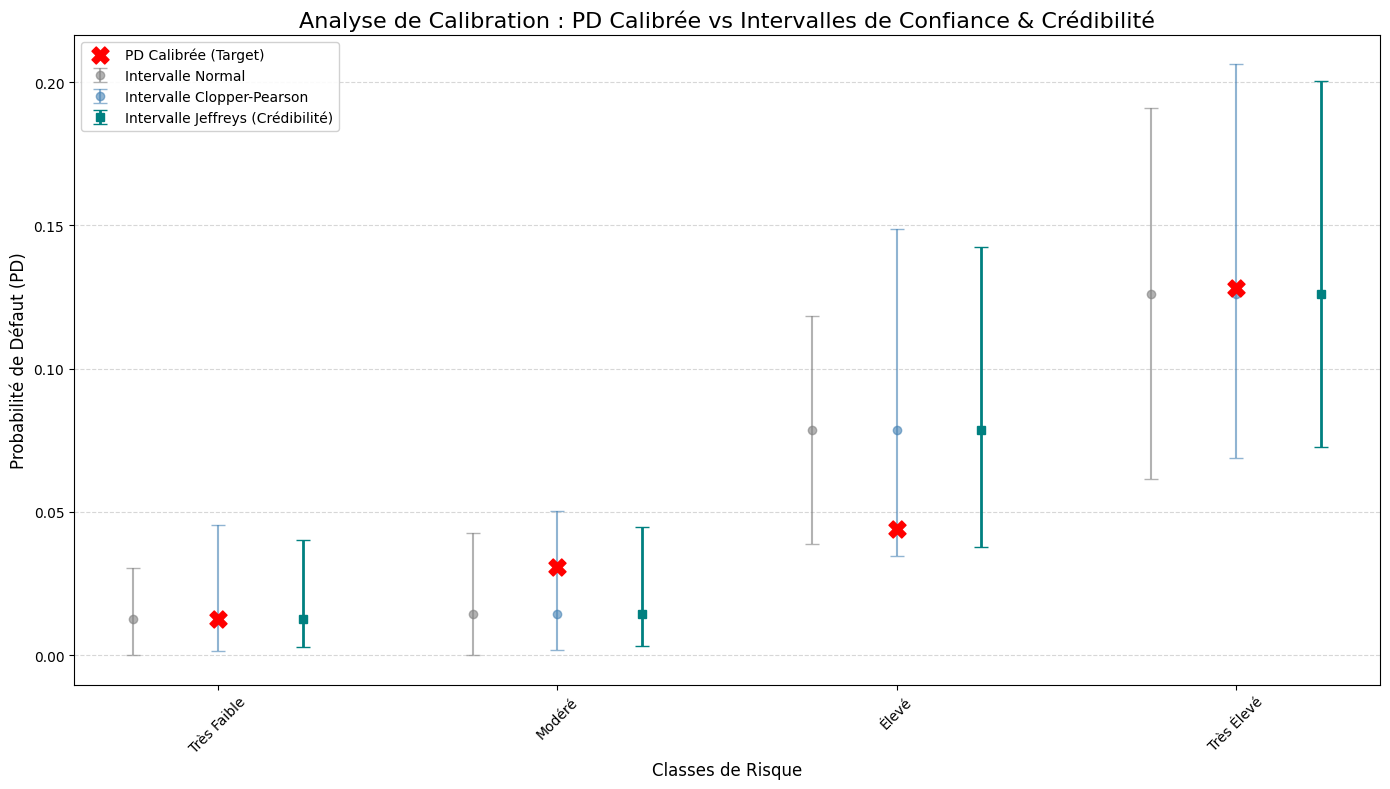

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Supposons que df_calibration est déjà généré par votre code précédent
# df_calibration = ...

plt.figure(figsize=(14, 8))

# Configuration de l'axe X
n_groups = len(df_calibration)
indices = np.arange(n_groups)
width = 0.25  # Espace entre les barres d'un même groupe

# --- 1. Tracer les intervalles (Barres verticales) ---
# Note : errorbar prend des tailles relatives, donc on calcule (Centre - Inf) et (Sup - Centre)
# Le "Centre" visuel de l'intervalle est le Taux de Défaut Observé

# A. Intervalle Normal (Décalé à gauche)
y = df_calibration['taux_defaut_obs']
yerr_norm = [y - df_calibration['Norm_Inf'], df_calibration['Norm_Sup'] - y]
plt.errorbar(indices - width, y, yerr=yerr_norm, 
             fmt='o', capsize=5, color='gray', alpha=0.6, label='Intervalle Normal')

# B. Intervalle Clopper-Pearson (Au centre)
yerr_cp = [y - df_calibration['CP_Inf'], df_calibration['CP_Sup'] - y]
plt.errorbar(indices, y, yerr=yerr_cp, 
             fmt='o', capsize=5, color='steelblue', alpha=0.6, label='Intervalle Clopper-Pearson')

# C. Intervalle de Jeffreys (Décalé à droite - COULEUR DISTINCTE : Vert Sarcelle)
yerr_jef = [y - df_calibration['Jef_Inf'], df_calibration['Jef_Sup'] - y]
plt.errorbar(indices + width, y, yerr=yerr_jef, 
             fmt='s', capsize=5, color='teal', linewidth=2, label='Intervalle Jeffreys (Crédibilité)')


# --- 2. Tracer la PD Calibrée (Le point de comparaison) ---
# On trace un grand marqueur rouge sur l'axe pour voir s'il est "dans" les intervalles
plt.scatter(indices, df_calibration['PD_Calibrée_LR'], 
            color='red', marker='X', s=150, zorder=10, label='PD Calibrée (Target)')


# --- 3. Mise en forme ---
plt.title('Analyse de Calibration : PD Calibrée vs Intervalles de Confiance & Crédibilité', fontsize=16)
plt.ylabel('Probabilité de Défaut (PD)', fontsize=12)
plt.xlabel('Classes de Risque', fontsize=12)

# Étiquettes de l'axe X
if 'risk_groups' in df_calibration.columns:
    labels = df_calibration['risk_groups']
elif 'intervals' in df_calibration.columns:
    labels = df_calibration['intervals'].astype(str)
else:
    labels = df_calibration.index

plt.xticks(indices, labels, rotation=45)
plt.legend(loc='upper left', frameon=True, fancybox=True, framealpha=0.9)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

***---Résultats unilatéraux---***

In [23]:
# Application de la fonction
unilat_res = summary_backtest.apply(
    lambda x: get_unilateral_metrics(x['Défauts_Obs'], x['N_Valid'], x['PD_Calibrée_LR']), axis=1
)

# Création du DataFrame final pour le conservatisme
cols_unilat = ['Norm_Sup_Unilat', 'CP_Sup_Unilat', 'Jef_Sup_Unilat', 'P_Value_Jeffreys']
df_conservatisme = summary_backtest[["intervals",'Défauts_Obs','N_Valid', 'PD_Calibrée_LR','taux_defaut_obs','Taux_Défaut_Jeffrey']].copy()
df_conservatisme[cols_unilat] = pd.DataFrame(unilat_res.tolist(), index=summary_backtest.index)

# Arrondis à 4 chiffres
df_conservatisme = df_conservatisme.round(4)

print("--- TABLEAU 6 : ANALYSE DU CONSERVATISME (BORNES SUPÉRIEURES UNILATÉRALES) ---")
display(df_conservatisme)

--- TABLEAU 6 : ANALYSE DU CONSERVATISME (BORNES SUPÉRIEURES UNILATÉRALES) ---


,intervals,Défauts_Obs,N_Valid,PD_Calibrée_LR,taux_defaut_obs,Taux_Défaut_Jeffrey,Norm_Sup_Unilat,CP_Sup_Unilat,Jef_Sup_Unilat,P_Value_Jeffreys
0,"(0.010700000000000001, 0.0155]",2,157,0.0127,0.0127,0.0158,0.0274,0.0396,0.0348,0.4497
1,"(0.0155, 0.033]",2,141,0.0306,0.0142,0.0176,0.0380,0.0440,0.0387,0.8791
2,"(0.033, 0.0535]",8,102,0.0441,0.0784,0.0825,0.1119,0.1371,0.1311,0.0554
3,"(0.0535, 0.895]",13,103,0.1283,0.1262,0.1298,0.1804,0.1932,0.1876,0.5106


***Commentaire***:  
 - Dans l'analyse présentée au Tableau 6, nous comparons les trois approches de validation pour la catégorie "Très Faible". On observe que le test de Jeffreys produit une borne supérieure unilatérale de 3,48 %, tandis que la méthode de Clopper-Pearson s'élève à 3,96 % et l'approximation normale descend à 2,74 %.

- Cette divergence de résultats illustre parfaitement le conservatisme excessif des méthodes fréquentistes exactes (Clopper-Pearson) et, à l'inverse, la tendance de l'approximation normale à sous-estimer le risque lorsqu'elle est appliquée à des échantillons de taille réduite.

- En conclusion, le test de Jeffreys permet à l'institution financière d'optimiser son allocation de fonds propres — en "sauvant du capital" par rapport à Clopper-Pearson — tout en garantissant une robustesse statistique supérieure à l'approche normale, particulièrement dans les contextes critiques de faibles taux de défaut (LDP).


> ***En conclusion, le test de jeffreys permet à la banque de "sauver du capital" par rapport à Clopper-Pearson, tout en étant statistiquement plus solide que l'approximation normale.***

***III.4.3 Calcul des p-values de Jeffreys pour évaluer le Conservatisme de la probabilité de défauts calibrée***  


Cette étape finale permet de répondre à l'exigence de conservatisme imposée par le Guide de la BCE sur les modèles internes. Dans ce contexte, la p-value de Jeffreys n'est pas un test de rejet classique, mais une mesure de la "marge de prudence".  


La p-value de Jeffreys dans ce cadre correspond à la probabilité cumulée de la loi Beta (la fonction de répartition) évaluée à la valeur de la PD prédite.  

- Si la p-value est proche de 1, la PD prédite est très au-dessus du taux observé (très conservateur).  

- Si la p-value est proche de 0, la PD prédite est peut-être trop optimiste (sous-estimation du risque).  

***Analyse du Conservatisme (Test de Jeffreys - Recommandations BCE)***

| P-value de Jeffreys | Interprétation (BCE) | État du Modèle |
| :--- | :--- | :--- |
| **> 0.90** (ex: Catégorie 1) | **Fort conservatisme**. La PD prédite est bien plus élevée que ce que les données montrent. | **Validé** (Très prudent) |
| **~ 0.50** | **Alignement parfait**. Le modèle prédit exactement la tendance centrale des données observées. | **Validé** (Neutre) |
| **< 0.10** | **Sous-estimation potentielle**. Le taux de défaut réel dépasse dangereusement la prédiction. | **Alerte** (Manque de prudence) |

Code de calcul p.value

In [24]:
from scipy.stats import beta

def get_jeffreys_p_value(k, n, pd_calibrated):
    """
    Calcule la p-value unilatérale de Jeffreys.
    k : nombre de défauts observés
    n : nombre d'observations
    pd_calibrated : la PD que le modèle a prédite (PD_Long_Run)
    """
    if n == 0:
        return np.nan
    
    # La p-value de Jeffreys est la CDF de la loi Beta(k+0.5, n-k+0.5)
    # évaluée au niveau de la PD calibrée.
    p_value = beta.cdf(pd_calibrated, k + 0.5, n - k + 0.5)
    return p_value

# Application sur les résultats de backtesting
summary_backtest_pvalue = summary_backtest.copy()
summary_backtest_pvalue['P_Value_Jeffreys'] = summary_backtest.apply(
    lambda x: get_jeffreys_p_value(x['Défauts_Obs'], x['N_Valid'], x['PD_Calibrée_LR']), 
    axis=1
)

# Arrondis à 3 chiffres
summary_backtest_pvalue = summary_backtest_pvalue.round(3)

# Présentation des résultats
print("--- TABLEAU 6 : ANALYSE DU CONSERVATISME (P-VALUES DE JEFFREYS) ---")
display(summary_backtest_pvalue[['Défauts_Obs', 'N_Valid', 'PD_Calibrée_LR', 'P_Value_Jeffreys']])

--- TABLEAU 6 : ANALYSE DU CONSERVATISME (P-VALUES DE JEFFREYS) ---


,Défauts_Obs,N_Valid,PD_Calibrée_LR,P_Value_Jeffreys
0,2,157,0.0127,0.450
1,2,141,0.0306,0.879
2,8,102,0.0441,0.055
3,13,103,0.1283,0.511


Illustration graphique p.value

In [25]:
Data_unilateral_graph = df_conservatisme.copy()

C:\Users\HP 1030\AppData\Local\Temp\ipykernel_13024\2056348147.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:.1f}%'.format(v*100) for v in ax.get_xticks()])
C:\Users\HP 1030\AppData\Local\Temp\ipykernel_13024\2056348147.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:.1f}%'.format(v*100) for v in ax.get_xticks()])
C:\Users\HP 1030\AppData\Local\Temp\ipykernel_13024\2056348147.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:.1f}%'.format(v*100) for v in ax.get_xticks()])
C:\Users\HP 1030\AppData\Local\Temp\ipykernel_13024\2056348147.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fix

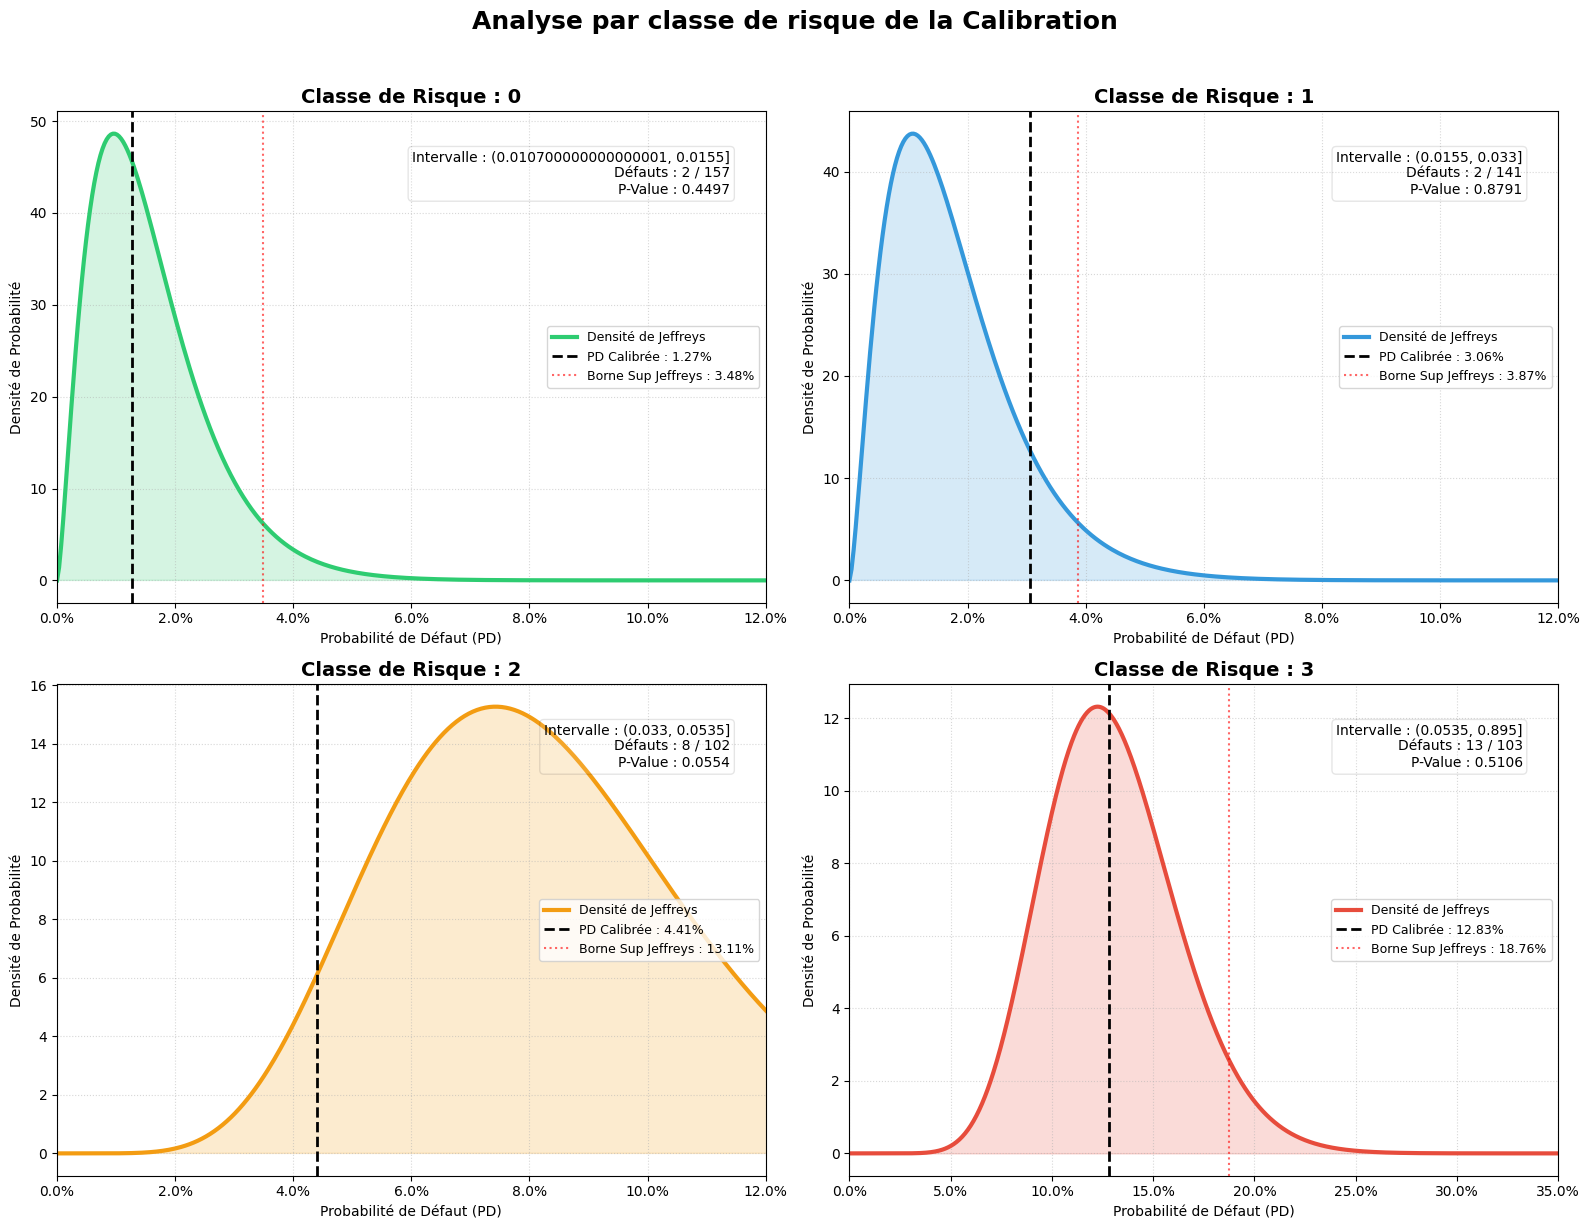

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

def plot_individual_posterior_densities(df_res):
    """
    Génère 4 graphiques (un par classe) à partir de Data_unilateral_graph
    Affiche la densité de Jeffreys, la PD calibrée et la P-Value associée.
    """
    # Configuration de la grille (2 lignes, 2 colonnes)
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    # Couleurs distinctes pour les classes
    colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c'] 
    x = np.linspace(0, 0.35, 1000) # Plage de PD de 0 à 35%

    # On suppose que l'index de votre DF contient les labels ('Très Faible', etc.)
    # Sinon, on peut utiliser df_res.index si ce sont les noms de catégories.
    for i, ((label, row), color) in enumerate(zip(df_res.iterrows(), colors)):
        ax = axes[i]
        
        # Extraction des données selon vos colonnes exactes
        k = row['Défauts_Obs']
        n = row['N_Valid']
        pd_calib = row['PD_Calibrée_LR']
        p_value = row['P_Value_Jeffreys']
        interval_label = row['intervals']
        
        # Calcul de la loi Beta a posteriori (Prior de Jeffreys : alpha=0.5, beta=0.5)
        alpha_post = k + 0.5
        beta_post = (n - k) + 0.5
        y_pdf = beta.pdf(x, alpha_post, beta_post)
        
        # 1. Tracé de la courbe de densité
        ax.plot(x, y_pdf, color=color, lw=3, label='Densité de Jeffreys')
        ax.fill_between(x, 0, y_pdf, color=color, alpha=0.2)
        
        # 2. Marquage de la PD Calibrée (Ligne verticale noire)
        ax.axvline(pd_calib, color='black', linestyle='--', lw=2, 
                   label=f'PD Calibrée : {pd_calib:.2%}')
        
        # 3. Affichage de la borne supérieure de Jeffreys (Unilatérale)
        # Puisque vous avez 'Jef_Sup_Unilat', on peut la marquer comme limite de prudence
        ax.axvline(row['Jef_Sup_Unilat'], color='red', linestyle=':', alpha=0.6, 
                   label=f'Borne Sup Jeffreys : {row["Jef_Sup_Unilat"]:.2%}')

        # 4. Boîte de texte pour les statistiques
        # Si la p-value est < 5%, on met un fond rouge (Alerte sous-estimation)
        bg_color = 'red' if p_value < 0.05 else 'white'
        stats_text = (f"Intervalle : {interval_label}\n"
                      f"Défauts : {int(k)} / {int(n)}\n"
                      f"P-Value : {p_value:.4f}")
        
        ax.text(0.95, 0.92, stats_text, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor=bg_color, alpha=0.1))

        # Configuration des axes
        ax.set_title(f"Classe de Risque : {label}", fontsize=14, fontweight='bold')
        ax.set_xlabel("Probabilité de Défaut (PD)")
        ax.set_ylabel("Densité de Probabilité")
        
        # Zoom dynamique : on adapte l'axe X à la classe pour mieux voir
        if i == 3: # Classe 'Très Élevé'
            ax.set_xlim(0, 0.35)
        else:
            ax.set_xlim(0, max(0.12, pd_calib * 2))
            
        # Formatage de l'axe X en pourcentages
        ax.set_xticklabels(['{:.1f}%'.format(v*100) for v in ax.get_xticks()])
        ax.legend(loc='center right', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

    # Titre général
    plt.suptitle("Analyse par classe de risque de la Calibration", 
                 fontsize=18, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    plt.show()

# Exécution
plot_individual_posterior_densities(Data_unilateral_graph)

Graphiques 1

In [27]:

Data_bilateral_graph = df_calibration.copy()

Data_bilateral_graph.columns

Index(['intervals', 'risk_groups', 'Défauts_Obs', 'N_Valid', 'taux_defaut_obs',
       'PD_Calibrée_LR', 'Taux_Défaut_Jeffrey', 'Norm_Inf', 'Norm_Sup',
       'CP_Inf', 'CP_Sup', 'Jef_Inf', 'Jef_Sup'],
      dtype='object')

C:\Users\HP 1030\AppData\Local\Temp\ipykernel_13024\1330053246.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:.1f}%'.format(x*100) for x in ax.get_yticks()])


Graphique sauvegardé sous : comparaison_freq_bayes_classes.png


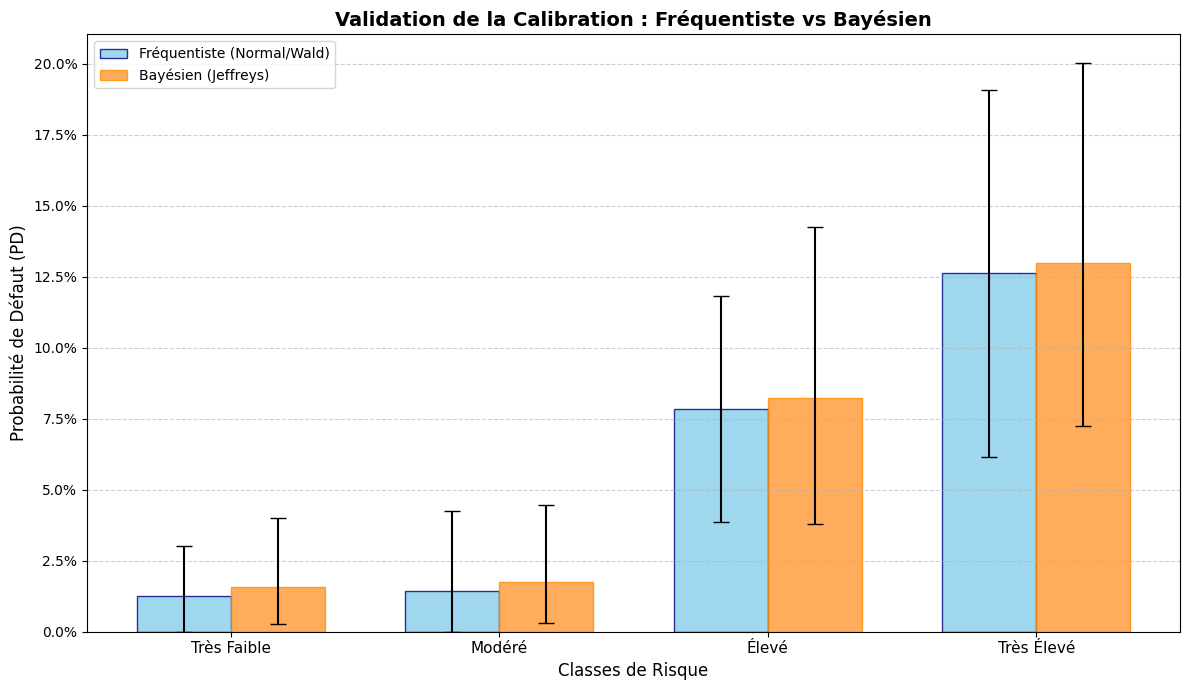

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# --- GRAPHIQUE 1 : COMPARAISON DES INTERVALLES PAR CLASSE DE RISQUE ---
def plot_intervals_comparison(df):
    # Création de la figure
    fig, ax = plt.subplots(figsize=(12, 7))
    
    indices = np.arange(len(df))
    width = 0.35
    
    # 1. Préparation des données Fréquentistes (Approximation Normale)
    # On utilise le taux observé comme estimation ponctuelle
    pd_freq = df['taux_defaut_obs']
    # Calcul des erreurs : [valeur - borne_inf, borne_sup - valeur]
    err_freq = [
        (pd_freq - df['Norm_Inf']).clip(lower=0), 
        (df['Norm_Sup'] - pd_freq).clip(lower=0)
    ]
    
    # 2. Préparation des données Bayésiennes (Jeffreys)
    # On utilise l'espérance a posteriori (Taux_Défaut_Jeffrey)
    pd_bayes = df['Taux_Défaut_Jeffrey']
    err_bayes = [
        (pd_bayes - df['Jef_Inf']).clip(lower=0), 
        (df['Jef_Sup'] - pd_bayes).clip(lower=0)
    ]
    
    # 3. Construction des barres
    # Barres Fréquentistes (Bleu)
    ax.bar(indices - width/2, pd_freq, width, yerr=err_freq, 
           label='Fréquentiste (Normal/Wald)', capsize=6, color='skyblue', edgecolor='navy', alpha=0.8)
    
    # Barres Bayésiennes (Orange)
    ax.bar(indices + width/2, pd_bayes, width, yerr=err_bayes, 
           label='Bayésien (Jeffreys)', capsize=6, color='#ff9933', edgecolor='darkorange', alpha=0.8)
    
    # 4. Mise en forme et habillage
    ax.set_ylabel('Probabilité de Défaut (PD)', fontsize=12)
    ax.set_xlabel('Classes de Risque', fontsize=12)
    ax.set_title('Validation de la Calibration : Fréquentiste vs Bayésien', fontsize=14, fontweight='bold')
    
    # Étiquettes de l'axe X (Noms des classes)
    ax.set_xticks(indices)
    ax.set_xticklabels(df['risk_groups'], fontsize=11)
    
    # Ajout d'une grille pour faciliter la lecture des pourcentages
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.legend(fontsize=10)
    
    # Formatage de l'axe Y en pourcentages (optionnel mais recommandé)
    ax.set_yticklabels(['{:.1f}%'.format(x*100) for x in ax.get_yticks()])
    
    plt.tight_layout()
    # Sauvegarde de l'image pour votre présentation
    plt.savefig('comparaison_freq_bayes_classes.png', dpi=300)
    print("Graphique sauvegardé sous : comparaison_freq_bayes_classes.png")

# Lancement de la fonction avec votre DataFrame
plot_intervals_comparison(Data_bilateral_graph )

Graphiques 2


Génération du Graphique 2 : Simulation du Cas Limite (0 défaut)...


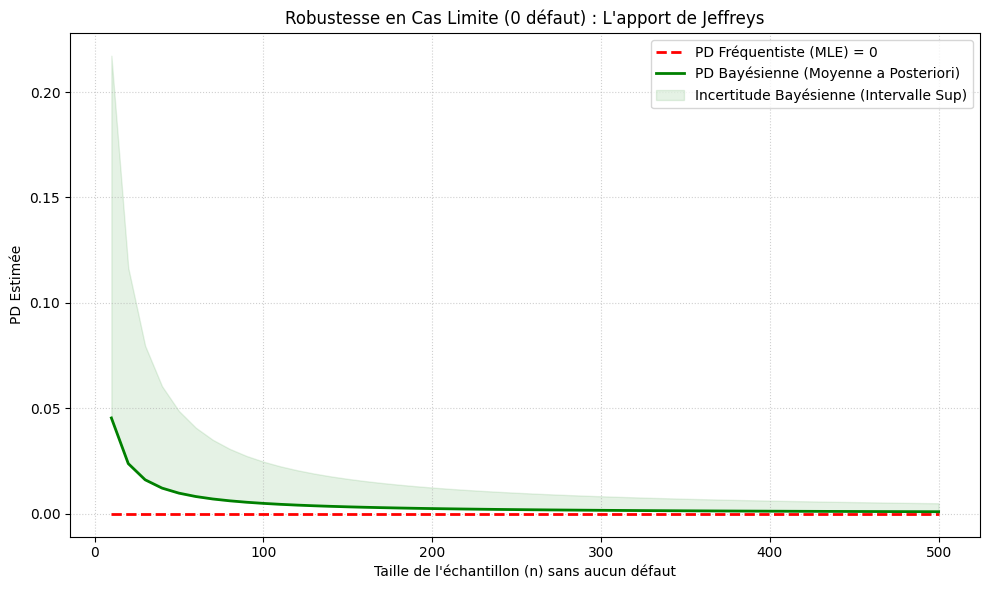

In [29]:
# --- GRAPHIQUE 2 : ANALYSE DU CAS LIMITE (ZÉRO DÉFAUT) ---
def plot_limiting_case():
    """
    Simule un portefeuille de taille n variant de 10 à 500 avec k=0 défauts.
    Montre comment l'estimateur Bayésien 'invente' du risque prudemment alors que le Fréquentiste reste à 0.
    """
    n_values = np.arange(10, 501, 10)
    k = 0
    
    pd_freqs = [k / n for n in n_values]
    pd_bayes = [(k + 0.5) / (n + 1) for n in n_values]
    
    # Intervalle sup Bayésien (Conservatisme)
    bayes_upper = [beta.ppf(0.975, k + 0.5, n - k + 0.5) for n in n_values]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.plot(n_values, pd_freqs, label='PD Fréquentiste (MLE) = 0', color='red', linestyle='--', linewidth=2)
    ax.plot(n_values, pd_bayes, label='PD Bayésienne (Moyenne a Posteriori)', color='green', linewidth=2)
    ax.fill_between(n_values, pd_bayes, bayes_upper, color='green', alpha=0.1, label='Incertitude Bayésienne (Intervalle Sup)')
    
    ax.set_xlabel("Taille de l'échantillon (n) sans aucun défaut")
    ax.set_ylabel("PD Estimée")
    ax.set_title("Robustesse en Cas Limite (0 défaut) : L'apport de Jeffreys")
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

print("\nGénération du Graphique 2 : Simulation du Cas Limite (0 défaut)...")
plot_limiting_case()

graphique 3

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- SYNTHÈSE DES RÉSULTATS (Sur la base de Data_unilateral_graph) ---
# On extrait les colonnes nécessaires de votre DataFrame existant
rows_emp = []
for idx, row in Data_bilateral_graph .iterrows():
    # Extraction des données réelles et calibrées
    k = int(row['Défauts_Obs'])
    n = int(row['N_Valid'])
    p0 = float(row['PD_Calibrée_LR']) # PD Calibrée cible
    p_mle = float(row['taux_defaut_obs']) # PD Observée (MLE)
    
    # Récupération des statistiques de Jeffreys déjà calculées
    post_mean = float(row['Taux_Défaut_Jeffrey'])
    cred_low = float(row['Jef_Inf'])
    cred_high = float(row['Jef_Sup'])
    
    # Récupération des statistiques Fréquentistes déjà calculées
    wlow = float(row['Norm_Inf'])
    whigh = float(row['Norm_Sup'])
    
    rows_emp.append({
        "Class": row['risk_groups'],
        "Défauts": k, 
        "N": n,
        "PD_Calib": p0,
        "PD_Obs": p_mle,
        "Jeff_PostMean": post_mean,
        "Jeff_CI_Low": cred_low,
        "Jeff_CI_High": cred_high,
        "Wald_Low": wlow,
        "Wald_High": whigh
    })

# Création du DataFrame de présentation finale
results_emp = pd.DataFrame(rows_emp).set_index("Class")
print("\n--- TABLEAU RÉCAPITULATIF : BACKTESTING (VALIDATION) ---")
display(results_emp.round(6))


--- TABLEAU RÉCAPITULATIF : BACKTESTING (VALIDATION) ---


,Défauts,N,PD_Calib,PD_Obs,Jeff_PostMean,Jeff_CI_Low,Jeff_CI_High,Wald_Low,Wald_High
Class,,,,,,,,,
Très Faible,2,157,0.0127,0.0127,0.0158,0.0027,0.0402,0.0000,0.0303
Modéré,2,141,0.0306,0.0142,0.0176,0.0030,0.0447,0.0000,0.0426
Élevé,8,102,0.0441,0.0784,0.0825,0.0378,0.1425,0.0386,0.1183
Très Élevé,13,103,0.1283,0.1262,0.1298,0.0726,0.2004,0.0616,0.1908


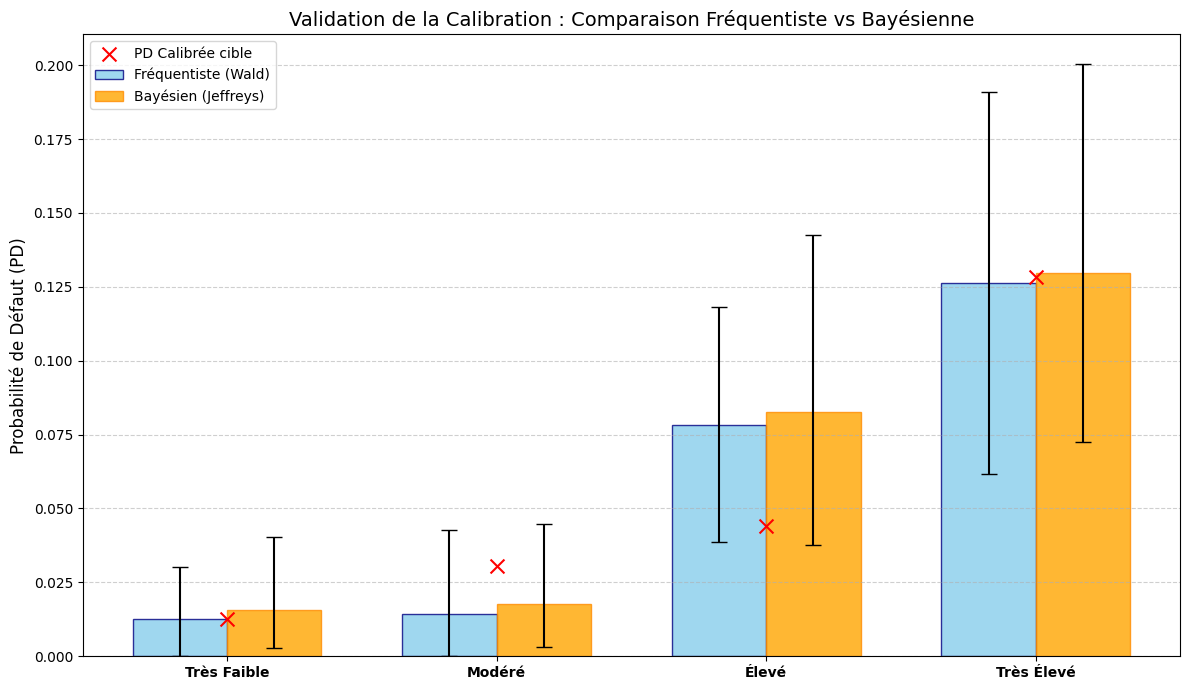

In [31]:
# --- GRAPHIQUE COMPARATIF : WALD VS JEFFREYS ---
fig, ax = plt.subplots(figsize=(12, 7))

idx = np.arange(len(results_emp))
w = 0.35

# Données Fréquentistes
pd_mle = results_emp["PD_Obs"].values
# .clip(lower=0) pour éviter les erreurs graphiques si Wald_Low est à 0
yerr_wald = [
    (pd_mle - results_emp["Wald_Low"]).clip(0).values, 
    (results_emp["Wald_High"] - pd_mle).clip(0).values
]

# Données Bayésiennes
post_mean = results_emp["Jeff_PostMean"].values
yerr_jef = [
    (post_mean - results_emp["Jeff_CI_Low"]).clip(0).values, 
    (results_emp["Jeff_CI_High"] - post_mean).clip(0).values
]

# Construction des barres d'erreur
ax.bar(idx - w/2, pd_mle, w, yerr=yerr_wald, capsize=6, 
       color='skyblue', edgecolor='navy', alpha=0.8, label="Fréquentiste (Wald)")
ax.bar(idx + w/2, post_mean, w, yerr=yerr_jef, capsize=6, 
       color='orange', edgecolor='darkorange', alpha=0.8, label="Bayésien (Jeffreys)")

# Ajout de la ligne de la PD Calibrée (Target) pour vérifier visuellement la calibration
ax.scatter(idx, results_emp["PD_Calib"], color='red', marker='x', s=100, 
           label="PD Calibrée cible", zorder=5)

# Mise en forme professionnelle
ax.set_xticks(idx)
ax.set_xticklabels(results_emp.index, fontweight='bold')
ax.set_ylabel("Probabilité de Défaut (PD)", fontsize=12)
ax.set_title("Validation de la Calibration : Comparaison Fréquentiste vs Bayésienne", fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

graphique 4

In [32]:
Data_unilateral_graph = df_conservatisme.copy()
Data_unilateral_graph.columns

Index(['intervals', 'Défauts_Obs', 'N_Valid', 'PD_Calibrée_LR',
       'taux_defaut_obs', 'Taux_Défaut_Jeffrey', 'Norm_Sup_Unilat',
       'CP_Sup_Unilat', 'Jef_Sup_Unilat', 'P_Value_Jeffreys'],
      dtype='object')


Génération du graphique des densités superposées...


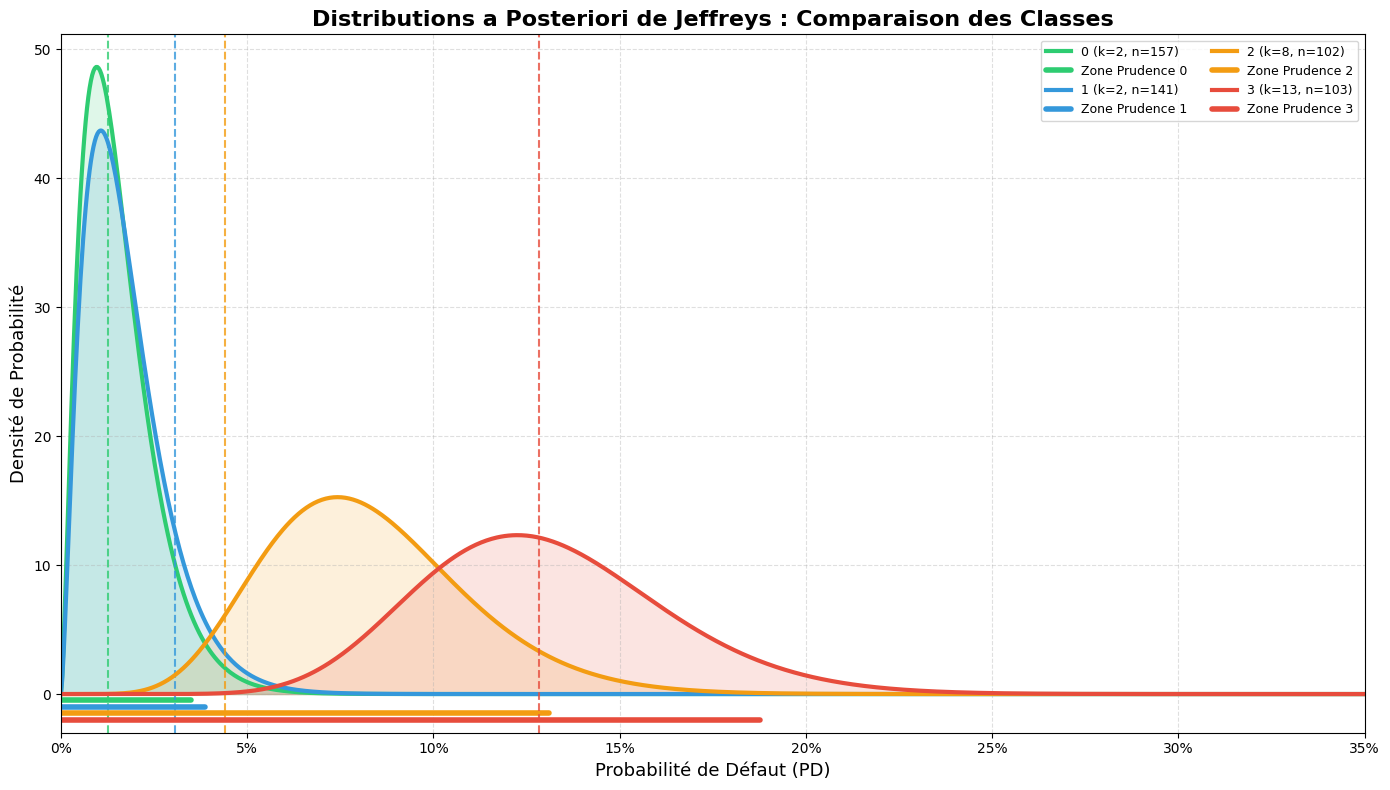

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

def plot_posterior_densities_combined(df_res):
    """
    Trace les courbes de densité Beta superposées pour chaque classe de risque
    en utilisant les paramètres de Data_unilateral_graph.
    """
    plt.figure(figsize=(14, 8))
    
    # Plage de PD à afficher (0 à 30% pour couvrir la classe Très Élevé)
    x = np.linspace(0, 0.35, 1000)
    # Palette de couleurs pour les 4 classes
    colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c'] 
    
    # On itère sur les lignes. idx correspond au label de la classe (ex: 'Très Faible')
    for (label, row), color in zip(df_res.iterrows(), colors):
        # Récupération des données selon vos colonnes
        k = row['Défauts_Obs']
        n = row['N_Valid']
        pd_calib = row['PD_Calibrée_LR']
        jef_sup = row['Jef_Sup_Unilat']
        
        # Paramètres de la loi Beta a posteriori (Prior de Jeffreys : 0.5, 0.5)
        alpha_post = k + 0.5
        beta_post = (n - k) + 0.5
        
        # Calcul de la densité (PDF)
        y = beta.pdf(x, alpha_post, beta_post)
        
        # 1. Tracé de la courbe de densité
        plt.plot(x, y, label=f"{label} (k={int(k)}, n={int(n)})", color=color, lw=3)
        plt.fill_between(x, 0, y, color=color, alpha=0.15)
        
        # 2. Ajout de la PD Calibrée (Ligne verticale pointillée)
        plt.axvline(pd_calib, color=color, linestyle='--', lw=1.5, alpha=0.8)
        
        # 3. Marquage de la borne supérieure unilatérale de Jeffreys au sol
        # On trace une ligne horizontale de 0 à la borne Jef_Sup_Unilat pour chaque classe
        # Décalage vertical léger pour ne pas superposer les barres au sol
        y_offset = - (df_res.index.get_loc(label) + 1) * 0.5
        plt.plot([0, jef_sup], [y_offset, y_offset], color=color, lw=4, 
                 solid_capstyle='round', label=f'Zone Prudence {label}')

    # Mise en forme du graphique
    plt.title("Distributions a Posteriori de Jeffreys : Comparaison des Classes", fontsize=16, fontweight='bold')
    plt.xlabel("Probabilité de Défaut (PD)", fontsize=13)
    plt.ylabel("Densité de Probabilité", fontsize=13)
    
    # Formatage de l'axe X en pourcentages
    plt.xticks(np.arange(0, 0.40, 0.05), [f'{int(val*100)}%' for val in np.arange(0, 0.40, 0.05)])
    
    plt.xlim(0, 0.35)
    plt.ylim(-3, None) # Espace pour les barres de zone de prudence en bas
    plt.grid(True, which='both', linestyle='--', alpha=0.4)
    plt.legend(loc='upper right', fontsize=9, frameon=True, ncol=2)
    
    plt.tight_layout()
    plt.show()

# Appel de la fonction
print("\nGénération du graphique des densités superposées...")
plot_posterior_densities_combined(Data_unilateral_graph)

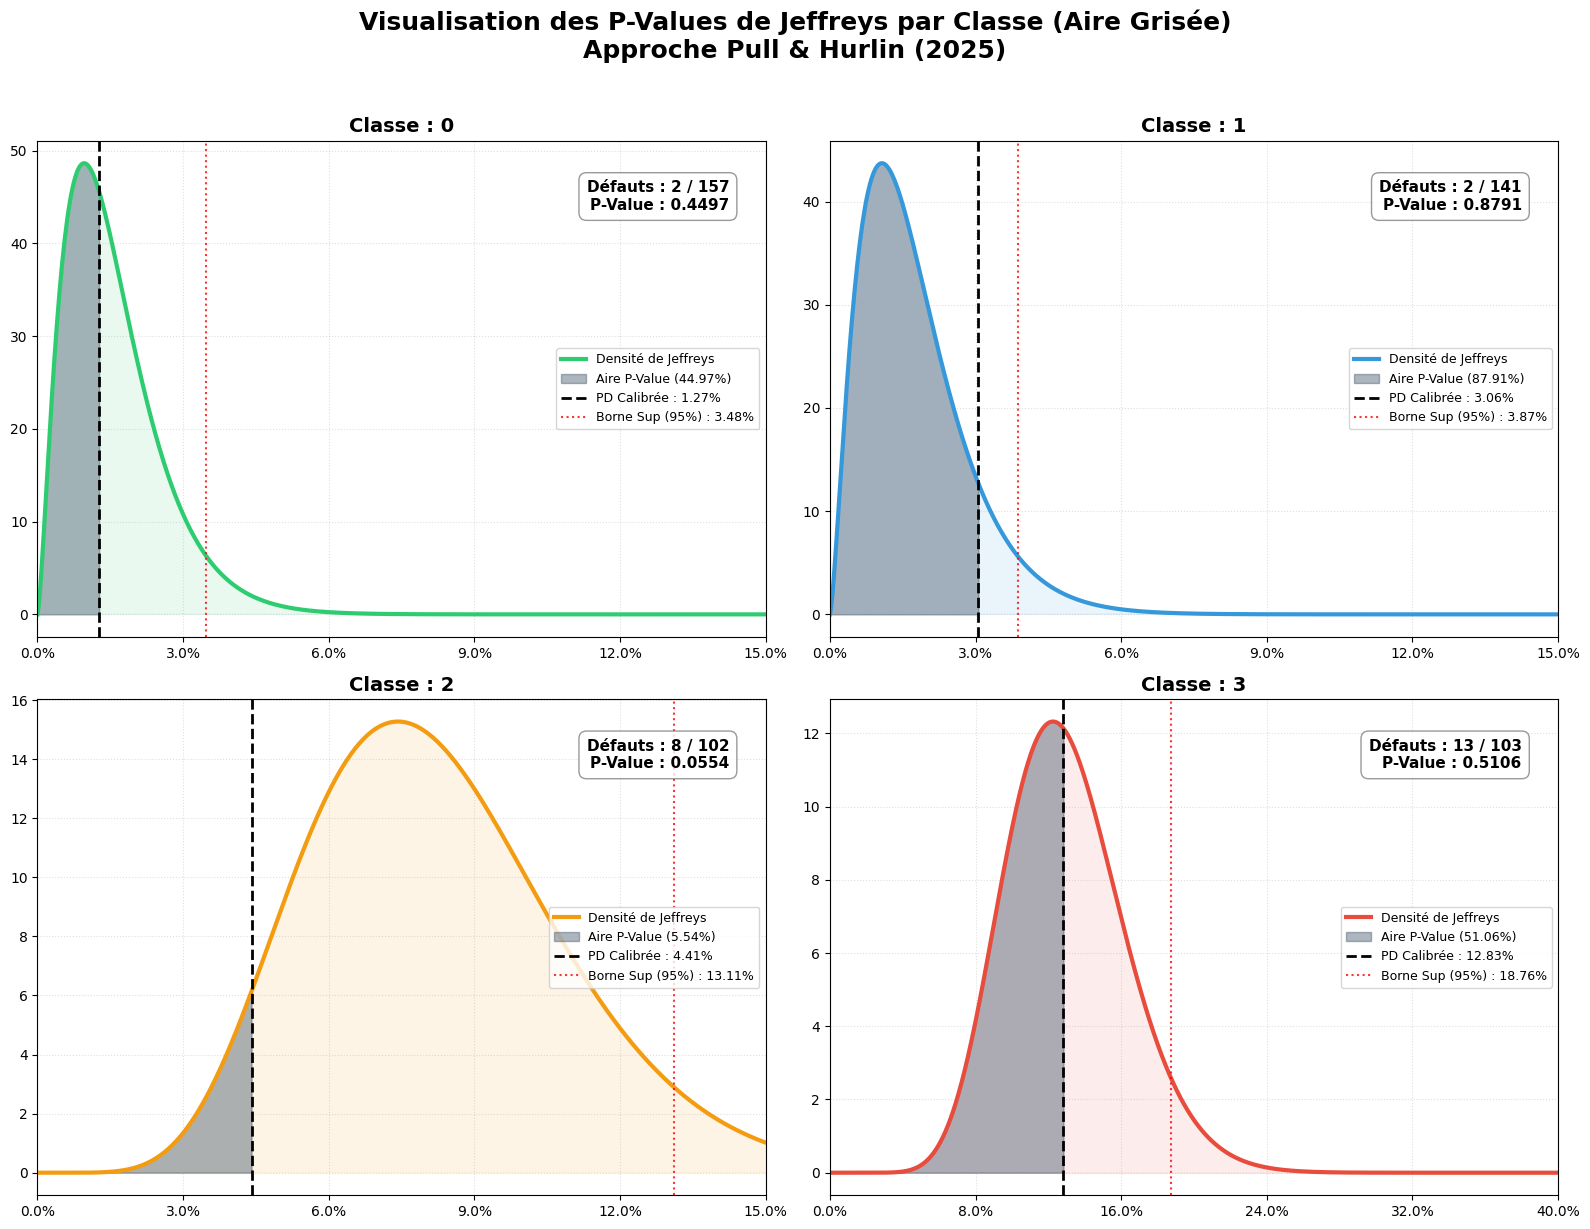

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

def plot_individual_posterior_densities(df_res):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c'] 
    # Couleur spécifique pour l'aire de la p-value (gris bleuté pour le contraste)
    pval_area_color = '#34495e' 
    x = np.linspace(0, 0.40, 1500)

    for i, ((label, row), color) in enumerate(zip(df_res.iterrows(), colors)):
        ax = axes[i]
        
        k, n = row['Défauts_Obs'], row['N_Valid']
        pd_calib = row['PD_Calibrée_LR']
        p_value = row['P_Value_Jeffreys']
        
        alpha_post = k + 0.5
        beta_post = (n - k) + 0.5
        y_pdf = beta.pdf(x, alpha_post, beta_post)
        
        # 1. Tracé de la courbe principale
        ax.plot(x, y_pdf, color=color, lw=3, label='Densité de Jeffreys')
        ax.fill_between(x, 0, y_pdf, color=color, alpha=0.1)
        
        # 2. COLORATION DE L'AIRE DE LA P-VALUE (de 0 à PD_calib)
        x_pval = np.linspace(0, pd_calib, 500)
        y_pval = beta.pdf(x_pval, alpha_post, beta_post)
        ax.fill_between(x_pval, 0, y_pval, color=pval_area_color, alpha=0.4, 
                        label=f'Aire P-Value ({p_value:.2%})')
        
        # 3. Marquages verticaux
        ax.axvline(pd_calib, color='black', linestyle='--', lw=2, 
                   label=f'PD Calibrée : {pd_calib:.2%}')
        
        # Borne supérieure de Jeffreys (Ligne rouge)
        ax.axvline(row['Jef_Sup_Unilat'], color='red', linestyle=':', alpha=0.8, 
                   label=f'Borne Sup (95%) : {row["Jef_Sup_Unilat"]:.2%}')

        # 4. Habillage et statistiques
        bg_color = '#fadbd8' if p_value < 0.05 else 'white'
        stats_text = (f"Défauts : {int(k)} / {int(n)}\n"
                      f"P-Value : {p_value:.4f}")
        
        ax.text(0.95, 0.92, stats_text, transform=ax.transAxes, fontsize=11,
                verticalalignment='top', horizontalalignment='right', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor=bg_color, edgecolor='gray', alpha=0.8))

        ax.set_title(f"Classe : {label}", fontsize=14, fontweight='bold')
        ax.set_xlim(0, max(0.15, pd_calib * 2.5) if i < 3 else 0.40)
        
        # Formatage axe X
        ax.set_xticks(np.linspace(0, ax.get_xlim()[1], 6))
        ax.set_xticklabels(['{:.1f}%'.format(v*100) for v in ax.get_xticks()])
        ax.legend(loc='center right', fontsize=9, frameon=True)
        ax.grid(True, linestyle=':', alpha=0.4)

    plt.suptitle("Visualisation des P-Values de Jeffreys par Classe (Aire Grisée)\nApproche Pull & Hurlin (2025)", 
                 fontsize=18, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

plot_individual_posterior_densities(Data_unilateral_graph)